# Advanced Automation 2025/26 - Assignment 1

To be delivered until 2025-12-19 23:59:59.

**Submission Notes**:
- Create a folder in your group's GitHub repository to solve this assignment. Copy this notebook into that folder.
- You should commit regularly to your repository the answers to the questions in this notebook. If you do not, your grade will be penalized by 1/20 points.
- After running the entire notebook (including graphs and outputs), save the notebook as a .pdf file, by going to File - Print - Destination: Save as PDF.
- Create a .zip file containing both the .ipynb file (the notebook itself) and the .pdf and submit it in Fénix.

# Part 1 - Arduino

1. Set up a series of connections in order to extract sensor data with the Arduino. First make the connections as shown below. **Mind the direction of the temperature sensor. If you have an incorrect position, you will be connection the power to the ground and vice-versa and you will damage the sensor.** The photoresistor sensor on the other hand has no polarity.

<img src="arduino_sensor_schematic.png" width=1000/>

**1.1.** Code an Arduino sketch, where the value of temperature and luminance are printed to the serial monitor. For each serial print that you make, print the value of temperature, then a semicolon, then the value of luminance with a new line (use no whitespaces). You can do this by using three separate `Serial.print`, with the last one being a `Serial.println`. Print values 5 times per second (use the delay function to control this). Manually influence the readings of the sensors, by covering the photoresistor or shining light on it, and by lightly and carefully touching the temperature sensor to increase its temperature readings. Copy and paste your arduino code below. You may use a python code cell, even though the code can not be run.



*Hint: for the temperature value to be in Celsius, divide the read value by 1024 and multiply it by 500. The luminance does not have to be converted. Note that the temperature sensor appears not to be very reliable. Since the objective of this exercise is just to plot the results, this should not be an issue.*

In [2]:
# Este código é Arduino C++, mas pode ser colocado numa célula Python como pedido

void setup() {
  Serial.begin(9600);
}

void loop() {
  // Ler sensores
  int tempRaw = analogRead(A0);     // temperatura analógica
  int lumRaw  = analogRead(A1);     // fotoresistor

  // Converter temperatura (hint do enunciado)
  float temperatureC = (tempRaw / 1024.0) * 500.0;

  // Imprimir no formato pedido: temperature;luminance
  Serial.print(temperatureC);
  Serial.print(";");
  Serial.println(lumRaw);

  // 5 vezes por segundo (1000 ms / 5)
  delay(200);
}

SyntaxError: invalid syntax (51455342.py, line 3)

To import the data into Arduino, keep it running (the Serial Monitor must be closed in Arduino) and run the following code. Change the COM port to your own. This block of code will read 500 values from the Serial. Given that each observation is taken every 0.2 seconds, it should take a minute and a half.

In [ ]:
import serial
import time

ser = serial.Serial('COM3', 9600, timeout=1)
time.sleep(2)

data = []
for i in range(500):
    line = ser.readline()
    if line:
        string = line.decode()
        data.append(string)

ser.close()


AttributeError: module 'serial' has no attribute 'Serial'

**1.2.** Convert the data into a pandas dataframe and save it in a `.csv` file. In addition to the temperature and luminance values, also include the elapsed time, considering the first observation at $t=0$ and every observation 0.2 seconds after the previous one. Add the `.csv` file to your submission in Fenix and upload it to your GitHub repository.

In [ ]:
import pandas as pd

# Supondo que guardaste os dados serializados (temperature;luminance)
# num ficheiro de texto chamado "arduino_log.txt"
# Cada linha tem o formato: 24.51;672

# Carregar os dados num DataFrame
data = pd.read_csv("arduino_log.txt", 
                   sep=";", 
                   header=None, 
                   names=["temperature", "luminance"])

# Criar a coluna elapsed_time
# A primeira observação é t = 0
# E cada observação ocorre 0.2 segundos depois da anterior
data["elapsed_time"] = data.index * 0.2

# Verificar os primeiros valores
print(data.head())

# Guardar em CSV para entregar no Fenix e no GitHub
data.to_csv("sensor_readings.csv", index=False)


FileNotFoundError: [Errno 2] No such file or directory: 'arduino_log.txt'

**1.3.** Plot the emperature against time, the luminance against time and the temperature against the luminosity. **(1.00)**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("sensor_readings.csv")

plt.figure(figsize=(8, 4))
plt.plot(data["elapsed_time"], data["temperature"], label="Temperature (°C)")
plt.xlabel("Time (s)")
plt.ylabel("Temperature (°C)")
plt.title("Temperature vs Time")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(data["elapsed_time"], data["luminance"], color="orange", label="Luminance")
plt.xlabel("Time (s)")
plt.ylabel("Luminance (raw value)")
plt.title("Luminance vs Time")
plt.grid(True)
plt.show()

plt.figure(figsize=(6, 6))
plt.scatter(data["luminance"], data["temperature"], alpha=0.7)
plt.xlabel("Luminance (raw value)")
plt.ylabel("Temperature (°C)")
plt.title("Temperature vs Luminance")
plt.grid(True)
plt.show()

# Part 2 - Databases

For this part of the assignment, you will use the mimic-iii database from the laboratory classes. Start by adding a few new tables to the database, using the SQL files included in the assignment's files. Open PGAdmin and connect to your mimic-iii database.

To properly load these tables, first run `demographic.sql` and then run `lab_firstday.sql`.


**2.1.** Open the connection to your mimic-iii database. **(0.50)**

If you want, you can delete your credentials before submitting the assignment, but if you do so, please run the notebook first, for the results to be displayed.

In [3]:
import pandas as pd
import numpy as np
import psycopg2 as psql
import matplotlib.pyplot as plt

conn = psql.connect(host='localhost',
                    database='mimic-iii',
                    user='postgres',
                    password='123456',
                    port=5432)

cursor = conn.cursor()

cursor.execute("select version()")

data = cursor.fetchone()
print("Connection established to: ", data)

Connection established to:  ('PostgreSQL 18.1 on x86_64-apple-darwin23.6.0, compiled by Apple clang version 16.0.0 (clang-1600.0.26.6), 64-bit',)


**2.2.**
Create a function that receives an SQL query and automatically opens a cursor, queries the database, extracts the columns, creates a pandas database, and closes the connections.
**(0.50)**

In [4]:
import pandas as pd

def run_query(query):
    """
    Receives an SQL query, opens a cursor, executes the query,
    extracts column names, builds a pandas DataFrame,
    closes cursor and returns the results.
    """

    cursor = conn.cursor()
    cursor.execute(query)

    # column names
    colnames = [desc[0] for desc in cursor.description]

    # data
    data = cursor.fetchall()

    cursor.close()

    # convert to DataFrame
    df = pd.DataFrame(data, columns=colnames)
    return df


**2.3.**
Query the table admissions filtering for admission type as elective and insurance as private.
**(1.00)**

In [5]:
query_23 = """
SELECT *
FROM admissions
WHERE admission_type = 'ELECTIVE'
  AND insurance = 'Private';
"""

df_23 = run_query(query_23)
df_23.head()

,row_id,subject_id,hadm_id,admittime,dischtime,deathtime,admission_type,admission_location,discharge_location,insurance,language,religion,marital_status,ethnicity,edregtime,edouttime,diagnosis,hospital_expire_flag,has_chartevents_data
0,12315,10065,183314,2189-09-08 07:15:00,2189-09-20 14:00:00,None,ELECTIVE,PHYS REFERRAL/NORMAL DELI,SNF,Private,ENGL,CATHOLIC,SINGLE,WHITE,None,None,ESOPHAGEAL CANCER/SDA,0,1
1,40972,43798,130870,2198-06-29 07:15:00,2198-08-07 23:59:00,None,ELECTIVE,PHYS REFERRAL/NORMAL DELI,HOME HEALTH CARE,Private,ENGL,CATHOLIC,MARRIED,WHITE,None,None,ESOPHAGEAL CA/SDA,0,1
2,41053,44083,125157,2112-05-04 08:00:00,2112-05-11 14:15:00,None,ELECTIVE,PHYS REFERRAL/NORMAL DELI,HOME HEALTH CARE,Private,ENGL,CATHOLIC,SINGLE,WHITE,None,None,ESOPHAGEAL CA/SDA,0,1


**2.4.**
Query the table admissions, filtering for the same conditions as the previous exercise (admission type as elective and insurance as private). Join the "drgcodes" table on the admission ID. Display only the columns regarding the subject id, admission id, time of death, and description of the drug.
**(1.00)**

In [6]:
query_24 = """
SELECT 
    adm.subject_id,
    adm.hadm_id,
    pat.dod,
    drg.description
FROM admissions adm
INNER JOIN drgcodes drg
    ON adm.hadm_id = drg.hadm_id
INNER JOIN patients pat
    ON adm.subject_id = pat.subject_id
WHERE adm.admission_type = 'ELECTIVE'
  AND adm.insurance = 'Private';
"""

df_24 = run_query(query_24)
df_24.head()

,subject_id,hadm_id,dod,description
0,10065,183314,2193-11-06,"STOMACH, ESOPHAGEAL & DUODENAL PROC AGE >17 W ..."
1,10065,183314,2193-11-06,"Major Stomach, Esophageal & Duodenal Procedures"
2,43798,130870,2200-12-31,"TRACH W MV 96+ HRS OR PDX EXC FACE, MOUTH & NE..."
3,43798,130870,2200-12-31,Tracheostomy W Long Term Mechanical Ventilatio...
4,43798,130870,2200-12-31,Tracheostomy W Long Term Mechanical Ventilatio...


**2.5.**
Explain how relational databases and graph databases model data. What are the advantages and disadvantages of each approach?
**(1.50)**

# Part 3 - Support Vector Machines

**3.1.**
Obtain the dataset for this problem, by running the SQL query below. After, close the connection to your SQL server.
**(0.50)**

In [7]:
query_31 = """
SELECT 
    pivoted_lab.*,
    demographics.gender,
    demographics.admission_age,
    demographics.ethnicity_grouped AS eth_grp,
    demographics.hospital_expire_flag,
    demographics.los_icu
FROM demographics
LEFT JOIN pivoted_lab
    ON demographics.icustay_id = pivoted_lab.icustay_id
WHERE first_icu_stay = true;
"""

df_31 = run_query(query_31)

if df_31 is not None:
    print("Dataset carregado com sucesso.")
    print(df_31.head())
else:
    print("ERRO.")

Dataset carregado com sucesso.
   subject_id  hadm_id  icustay_id  aniongap_min  aniongap_max  albumin_min  \
0       10006   142345      206504          12.0          20.0          2.7   
1       10011   105331      232110          12.0          12.0          2.6   
2       10013   165520      264446          13.0          13.0          NaN   
3       10017   199207      204881          13.0          13.0          2.8   
4       10019   177759      228977          20.0          46.0          3.2   

   albumin_max  bands_min  bands_max  bicarbonate_min  ...  sodium_max  \
0          3.4        NaN        NaN             29.0  ...       139.0   
1          2.6        2.0        2.0             23.0  ...       136.0   
2          NaN       13.0       13.0             29.0  ...       138.0   
3          2.8        NaN        NaN             29.0  ...       139.0   
4          3.2        NaN        NaN             10.0  ...       141.0   

   bun_min  bun_max  wbc_min  wbc_max  gender  ad

**3.2.** Prepare your dataset:

* Drop the ID columns of subject, admission and ICU stay.
* Drop columns with at least one NA value.
* Encode the categorical column: `eth_grp` and `gender`. *Suggestion: use pd.get_dummies*
* Divide the dataset into features and response. The response variable is `hospital_expire_flag`.
* Split the dataset into training (80%) and test (20%) sets. *Suggestion: split the data so that the proportion of positive and negative examples is the same in both sets.*

**(1.00)**


In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = df_31.copy()

cols_to_drop = ['subject_id', 'hadm_id', 'icustay_id']
df = df.drop(columns=cols_to_drop, errors='ignore')

df = df.dropna(axis=1)

df = pd.get_dummies(df, columns=['gender', 'eth_grp'], drop_first=True)

X = df.drop(columns=['hospital_expire_flag'])
y = df['hospital_expire_flag']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print(f"Train (X_train): {X_train.shape}")
print(f"Test (X_test): {X_test.shape}")
print(f"Remaining columns: {len(X.columns)}")

Train (X_train): (102, 29)
Test (X_test): (26, 29)
Remaining columns: 29


**3.3.**
Fit a Support Vector Machine (SVM) with a radial-basis function (RBF) kernel to the dataset. Set the hyperparameter cost $C=1$ and the hyperparameter gamma $\gamma=0.5$. Remember that SVMs are sensitive to the scale of the inputs.
**(1.00)**

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

svm_model = SVC(kernel='rbf', C=1.0, gamma=0.5, probability=True, random_state=42)

svm_model.fit(X_train_scaled, y_train)

print("SVM model successfully trained.")

SVM model successfully trained.


**3.4.**
Obtain the predictions for the model on the test set. Plot the receiver operating curve and calculate the AUC metric.
**(1.00)**

AUC Score: 0.3403


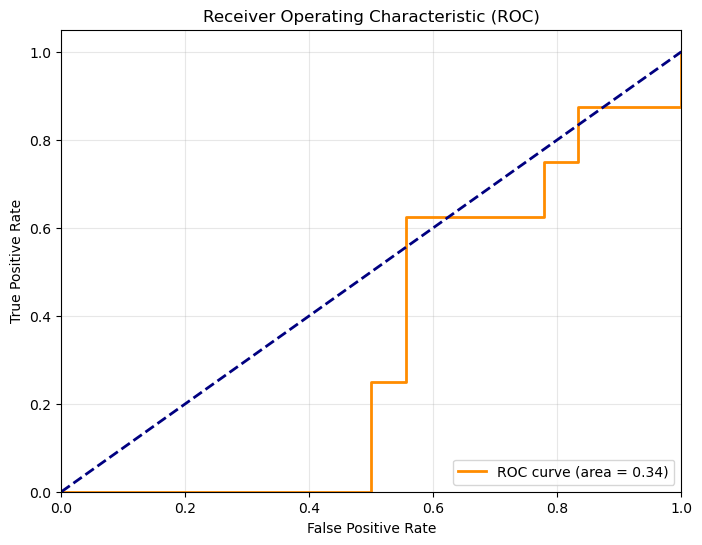

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, roc_auc_score

y_pred_proba = svm_model.predict_proba(X_test_scaled)[:, 1]

roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"AUC Score: {roc_auc:.4f}")

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # Linha de base (aleatória)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

**3.5.** Consider the $\gamma$ hyperparameter of the radial-basis function kernel. How does changing the value of $\gamma$ affect the decision boundary of the SVM? And how does it affect the bias and variance of the model?
**(2.00)**

The parameter gamma, dictates the range that a single training example exerts influence over, with low values taken to mean "far" and high values taken to mean "close." As gamma increases, so the decision boundary becomes more complex and irregular, tightens around individuals to fit the training set exactly; this results in low bias but high variance increasing the risk of overfitting. As gamma decreases, the decision boundary becomes smoother and simpler; this results in higher bias but lower variance increasing the risk of underfitting.

**3.6.**
Perform grid-search cross-validation on the SVM model, changing the values of $C$ and $\gamma$. Consider AUC as the performance measure. What are the best hyperparameters obtained?
**(2.00)**

In [11]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf']
}

grid = GridSearchCV(
    SVC(probability=True, random_state=42), 
    param_grid, 
    refit=True, 
    verbose=2, 
    scoring='roc_auc',
    cv=3
)

print("Starting Grid Search... this may take a while.")
grid.fit(X_train_scaled, y_train)

print("\nBest Parameters found:")
print(grid.best_params_)
print(f"Best AUC Score on Validation: {grid.best_score_:.4f}")

Starting Grid Search... this may take a while.
Fitting 3 folds for each of 16 candidates, totalling 48 fits
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   0.0s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   0.0s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   0.0s
[CV] END ......................C=0.1, gamma=0.01, kernel=rbf; total time=   0.0s
[CV] END ......................C=0.1, gamma=0.01, kernel=rbf; total time=   0.0s
[CV] END ......................C=0.1, gamma=0.01, kernel=rbf; total time=   0.0s
[CV] END .....................C=0.1, gamma=0.001, kernel=rbf; total time=   0.0s
[CV] END .....................C=0.1, gamma=0.001, kernel=rbf; total time=   0.0s
[

**3.7.**
Compute the AUC on the test set for the best model obtained in question 3.6.
Plot the ROC curve for the test set and compute the AUC metric.
Compare the performance with the model from **3.3**.
**(1.00)**

AUC do Melhor Modelo (GridSearch): 0.6319


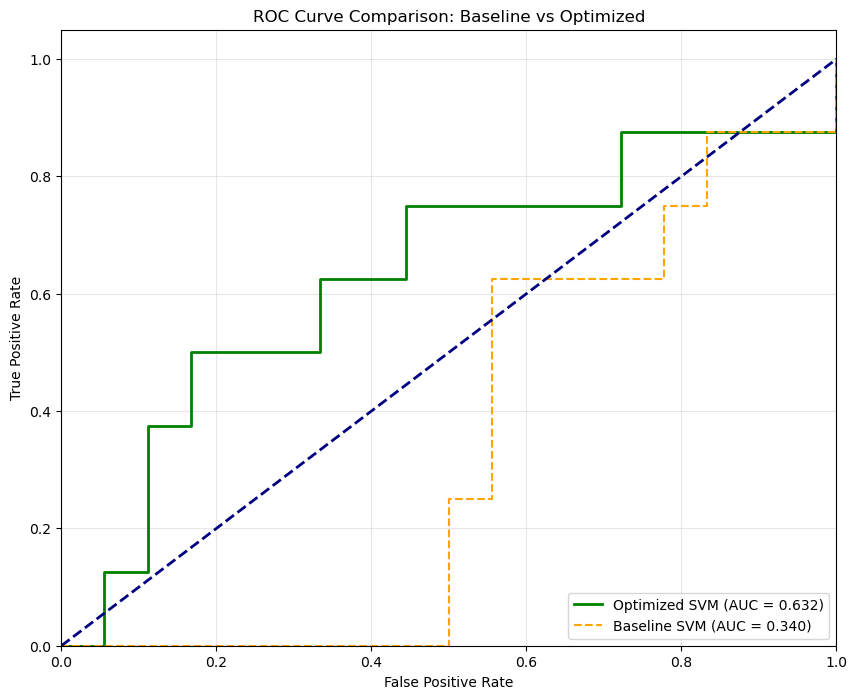

------------------------------
Performance Comparison:
Basic Model (3.3):     0.3403
Optimized Model (3.6): 0.6319
Improvement:           0.2917


In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

y_pred_proba_best = grid.predict_proba(X_test_scaled)[:, 1]

roc_auc_best = roc_auc_score(y_test, y_pred_proba_best)
print(f"AUC do Melhor Modelo (GridSearch): {roc_auc_best:.4f}")

fpr_best, tpr_best, thresholds_best = roc_curve(y_test, y_pred_proba_best)

plt.figure(figsize=(10, 8))

plt.plot(fpr_best, tpr_best, color='green', lw=2, 
         label=f'Optimized SVM (AUC = {roc_auc_best:.3f})')

if 'fpr' in locals() and 'tpr' in locals() and 'roc_auc' in locals():
    plt.plot(fpr, tpr, color='orange', linestyle='--', lw=1.5, 
             label=f'Baseline SVM (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison: Baseline vs Optimized')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

# 5. Comparação Numérica
print("-" * 30)
print("Performance Comparison:")
if 'roc_auc' in locals():
    print(f"Basic Model (3.3):     {roc_auc:.4f}")
    print(f"Optimized Model (3.6): {roc_auc_best:.4f}")
    print(f"Improvement:           {roc_auc_best - roc_auc:.4f}")
else:
    print(f"Optimized Model (3.6): {roc_auc_best:.4f}")

The optimized model, which was derived using a grid search cross-validation, got a better AUC value for the testing set compared to the first model derived in question 3.3. It is even better compared to the former, simply because a grid search technique involved the optimization of hyperparameters such as C and γ to optimize the AUC score, and such hyperparameters performed better compared to the arbitrary ones used previously.

# Part 4 - Tree-based Methods


**4.1.**
Explain how boosting works in tree-based methods. How does it differ from bagging? Does the technique aim to reduce bias or variance, and how?
**(1.50)**

In bagging, you divide the training data into "bags" that will have different data points. Then you train models on these different bags, and when the models are finished training, they vote to decide what the model thinks.

In this approach, the different models train in paralel, and they do not learn from each other.

In boosting however, each model learns from the previous one. The trees are made sequentially, and each time a new tree is made the data is weighted based on what the previous model failed on, so the features the previous model mislabeled become more significant.

It aims to reduce bias by correcting the errors of previous trees.

**4.2.** Fit a Gradient Boosting Classifier to the same dataset as in Part 3. Tune the learning rate and the max depth of the trees. How does the model perform on the test set compared to the SVM model?
**(2.50)**

Fitting 5 folds for each of 25 candidates, totalling 125 fits
[CV] END ....................learning_rate=0.01, max_depth=1; total time=   0.2s[CV] END ....................learning_rate=0.01, max_depth=1; total time=   0.2s

[CV] END ....................learning_rate=0.01, max_depth=1; total time=   0.2s
[CV] END ....................learning_rate=0.01, max_depth=1; total time=   0.2s
[CV] END ....................learning_rate=0.01, max_depth=1; total time=   0.2s
[CV] END ....................learning_rate=0.01, max_depth=2; total time=   0.2s
[CV] END ....................learning_rate=0.01, max_depth=2; total time=   0.2s
[CV] END ....................learning_rate=0.01, max_depth=2; total time=   0.2s
[CV] END ....................learning_rate=0.01, max_depth=2; total time=   0.2s
[CV] END ....................learning_rate=0.01, max_depth=2; total time=   0.2s
[CV] END ....................learning_rate=0.01, max_depth=3; total time=   0.3s
[CV] END ....................learning_rate=0.01

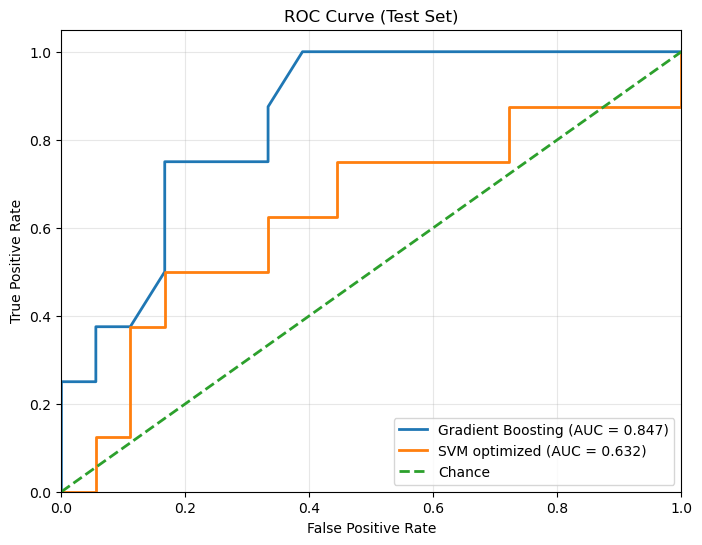

In [13]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# --- 4.2 Gradient Boosting: tune learning_rate and max_depth ---
gb = GradientBoostingClassifier(random_state=42)

param_grid = {
    "learning_rate": [0.01, 0.05, 0.1, 0.2, 0.3],
    "max_depth": [1, 2, 3, 4, 5],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_gb = GridSearchCV(
    gb,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=2,
)

grid_gb.fit(X_train, y_train)

best_gb = grid_gb.best_estimator_
print("Best Gradient Boosting params:", grid_gb.best_params_)
print(f"Best CV AUC (GB): {grid_gb.best_score_:.4f}")

# Test-set performance
y_proba_gb = best_gb.predict_proba(X_test)[:, 1]
auc_gb = roc_auc_score(y_test, y_proba_gb)
print(f"Test AUC (GB): {auc_gb:.4f}")

# Compare with SVM (if present from Part 3)
print("\n--- Comparison on test set ---")
if "roc_auc_best" in globals():
    print(f"SVM optimized (3.6) AUC: {roc_auc_best:.4f}")
elif "roc_auc" in globals():
    print(f"SVM basic (3.3) AUC:     {roc_auc:.4f}")
else:
    print("SVM AUC not found in variables (run Part 3 first).")
print(f"Gradient Boosting AUC:   {auc_gb:.4f}")

# ROC curves (GB + available SVM)
plt.figure(figsize=(8, 6))

fpr_gb, tpr_gb, _ = roc_curve(y_test, y_proba_gb)
plt.plot(fpr_gb, tpr_gb, lw=2, label=f"Gradient Boosting (AUC = {auc_gb:.3f})")

if "y_pred_proba_best" in globals() and "roc_auc_best" in globals():
    fpr_svm, tpr_svm, _ = roc_curve(y_test, y_pred_proba_best)
    plt.plot(fpr_svm, tpr_svm, lw=2, label=f"SVM optimized (AUC = {roc_auc_best:.3f})")
elif "y_pred_proba" in globals() and "roc_auc" in globals():
    fpr_svm, tpr_svm, _ = roc_curve(y_test, y_pred_proba)
    plt.plot(fpr_svm, tpr_svm, lw=2, label=f"SVM basic (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", lw=2, label="Chance")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Test Set)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()
